# 02 - Build the labeled set and train a baseline classifier

**Goal:** map every advertiser into one of the 10 verticals (plus an "Other / Unclassified" bucket).

**Input:** `data/processed/advertisers.csv` and `transactions_clean.csv` from notebook 01 (one row per de-duplicated advertiser, with revenue).
**Output:** a labeled/unlabeled split and a first baseline model (TF-IDF + Logistic Regression) with honest evaluation. Notebook 03 tries to beat it.

**Plan**
1. Fix the taxonomy and its boundary rules.
2. Decide *which* advertisers to label, spending effort where the revenue is.
3. Hold out a test set.
4. Train the simplest sensible model and evaluate it by count **and** by revenue.
5. Error analysis: what does it get wrong, and why?

In [1]:
import subprocess, sys
from pathlib import Path

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if not (ROOT / "src").exists():          # e.g. Google Colab
    subprocess.run(["git", "clone", "https://github.com/mayankg-data/advertiser-classification"], check=True)
    ROOT = ROOT / "advertiser-classification"
sys.path.insert(0, str(ROOT / "src"))

OUT = ROOT / "data" / "processed"
if not (OUT / "advertisers.csv").exists():      # run notebook 01 first if its outputs are missing
    subprocess.run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "--inplace",
                    str(ROOT / "notebooks" / "01_clean_and_dedupe.ipynb")], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline, make_union
from taxonomy import LABELS, VERTICALS, OTHER, BOUNDARY_RULES

pd.set_option("display.width", 140)
SEED = 42
adv = pd.read_csv(OUT / "advertisers.csv")
print(f"{len(adv):,} advertisers, total revenue ${adv.revenue_usd.sum():,.0f}")

2,362 advertisers, total revenue $94,446,819


## Step 1 - Taxonomy and boundary rules

The 10 verticals are a roll-up of the Google Ad Manager category tree into reporting groups, with an 11th **Other / Unclassified** bucket so obscure or out-of-scope advertisers are not forced into a wrong vertical. The key principle: **classify by what the advertiser sells, not where the ad runs or the channel they sell through.**

In [2]:
print("Labels:", *LABELS, sep="\n  - ")
print("\nBoundary rules:")
for r in BOUNDARY_RULES:
    print("  *", r)

Labels:
  - Automotive & Manufacturing
  - Finance
  - Internet & Telecom
  - Healthcare
  - Apparel & Fashion
  - Food & Beverage
  - Travel & Tourism
  - Entertainment & Media
  - Sports
  - Retail & E-commerce
  - Other / Unclassified

Boundary rules:
  * Supermarkets, department stores and marketplaces (Tesco, Walmart, Amazon, eBay) -> Retail & E-commerce
  * Food & Beverage is for producers and restaurant/food brands (Nestle, McDonald's)
  * Fashion retailers (ASOS, H&M) -> Apparel & Fashion: product category outweighs the channel
  * Sports apparel (Nike, Adidas) -> Apparel & Fashion; sports media, leagues, clubs -> Sports
  * Sports-betting-led brands (Paddy Power) -> Sports; other gambling (Bet365, William Hill) -> Other
  * Streaming and media -> Entertainment & Media; ISPs and tech platforms -> Internet & Telecom
  * Charities, education, property, recruitment and anything unclear -> Other / Unclassified


## Step 2 - Where to spend the labeling effort

**Important note on the labels.** In a real project these would come from people (or an LLM whose output a person reviews). Here the data is synthetic and the generator knows each advertiser's true vertical, so I use that as a stand-in for the human annotation. I only reveal it for the advertisers I "choose to label", and the model never sees the rest.

**Labeling plan (this mirrors how I would budget the effort):**
- **Tier 1 - top advertisers covering 90% of revenue:** label *all* of them. They are few, and any error here moves the revenue-by-vertical report the most.
- **Tier 2 - random sample of the long tail:** label a few hundred, so the model sees what small advertisers look like and so we can measure tail accuracy.
- Everything else stays **unlabeled** and will be predicted by the model.

The same advertiser can appear under several raw names, so I first attach the true vertical to each de-duplicated advertiser (revenue-weighted majority).

In [3]:
tx = pd.read_csv(OUT / "transactions_clean.csv")
variants = pd.read_csv(ROOT / "data" / "name_variants_truth.csv").drop_duplicates(["ssp", "advertiser_raw"])
gt = pd.read_csv(ROOT / "data" / "ground_truth.csv")[["canonical_advertiser", "vertical"]]

m = tx.merge(variants, on=["ssp", "advertiser_raw"]).merge(gt, on="canonical_advertiser")
true_vertical = (m.groupby(["advertiser_id", "vertical"]).revenue_usd.sum().reset_index()
                  .sort_values("revenue_usd", ascending=False).drop_duplicates("advertiser_id")
                  .set_index("advertiser_id").vertical)
adv["true_vertical"] = adv.advertiser_id.map(true_vertical)      # kept for evaluation; hidden unless "labeled"
assert adv.true_vertical.notna().all()

adv = adv.sort_values("revenue_usd", ascending=False).reset_index(drop=True)
adv["tier"] = np.where(adv.cum_share.shift(fill_value=0) < 0.90, "tier1_top90pct", "tier2_tail")

rng = np.random.default_rng(SEED)
tail_ids = adv.loc[adv.tier == "tier2_tail", "advertiser_id"].to_numpy()
tail_labeled = set(rng.choice(tail_ids, size=400, replace=False))
adv["labeled"] = (adv.tier == "tier1_top90pct") | adv.advertiser_id.isin(tail_labeled)

print(adv.groupby("tier").agg(advertisers=("advertiser_id", "size"), labeled=("labeled", "sum"),
                              revenue_share=("revenue_share", "sum")).round(3))
print(f"\nlabeled: {adv.labeled.sum()} advertisers = {adv.loc[adv.labeled, 'revenue_share'].sum():.1%} of revenue")

                advertisers  labeled  revenue_share
tier                                               
tier1_top90pct          405      405            0.9
tier2_tail             1957      400            0.1

labeled: 805 advertisers = 92.0% of revenue


Let me look at what we are working with: how many labeled advertisers per vertical, and how much revenue each vertical carries. The two views differ, which matters for evaluation.

,advertisers,revenue_share_%
true_vertical,,
Automotive & Manufacturing,72,9.7
Finance,86,11.6
Internet & Telecom,84,11.5
Healthcare,71,5.5
Apparel & Fashion,78,13.2
Food & Beverage,78,8.9
Travel & Tourism,86,9.7
Entertainment & Media,74,9.9
Sports,70,7.2


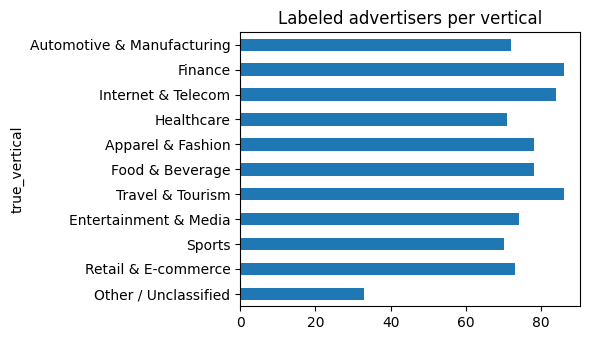

In [4]:
lab = adv[adv.labeled]
dist = pd.DataFrame({
    "advertisers": lab.true_vertical.value_counts(),
    "revenue_share_%": (lab.groupby("true_vertical").revenue_usd.sum() / lab.revenue_usd.sum() * 100).round(1),
}).reindex(LABELS)
display(dist)

ax = dist.advertisers.plot.barh(figsize=(6, 3.5), title="Labeled advertisers per vertical")
ax.invert_yaxis(); plt.tight_layout(); plt.show()

## Step 3 - Hold out a test set

25% of the labeled advertisers are set aside **before** any modelling and are never used for training or tuning. The split is **stratified by vertical** so each class appears in both sets.

Because notebook 01 already merged duplicate names into one advertiser, near-duplicates cannot leak between train and test. Without that step, `Tesco` in train and `TESCO LTD` in test would inflate the score.

In [5]:
lab = adv[adv.labeled].copy()
train, test = train_test_split(lab, test_size=0.25, stratify=lab.true_vertical, random_state=SEED)
print(f"train {len(train)} | test {len(test)}")
print("test set by tier:", test.tier.value_counts().to_dict())
adv["split"] = np.where(adv.advertiser_id.isin(train.advertiser_id), "train",
                np.where(adv.advertiser_id.isin(test.advertiser_id), "test", "unlabeled"))

train 603 | test 202
test set by tier: {'tier1_top90pct': 112, 'tier2_tail': 90}


## Step 4 - Baseline: TF-IDF + Logistic Regression

**Why start simple:** it is fast, cheap and interpretable, and it sets the bar any fancier model has to beat. If a transformer only improves things by one point, the added complexity is not worth it.

**Features:** the advertiser name only (that is all we have), as
- **character n-grams (2-5)** - pick up fragments like `bank`, `motor`, `air`, and survive typos and unusual spellings
- **word n-grams (1-2)** - pick up whole words like `airlines`

**Model:** Logistic Regression with `class_weight="balanced"`, because some verticals are much smaller than others. I tune the regularisation strength `C` with cross-validation on the **training set only**.

A majority-class dummy model is included as the floor.

In [6]:
def make_model(C=10):
    feats = make_union(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), lowercase=True, sublinear_tf=True),
        TfidfVectorizer(analyzer="word", ngram_range=(1, 2), lowercase=True, sublinear_tf=True),
    )
    return make_pipeline(feats, LogisticRegression(C=C, max_iter=2000, class_weight="balanced"))

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
scores = {C: cross_val_score(make_model(C), train.advertiser, train.true_vertical, cv=cv, scoring="f1_macro").mean()
          for C in [1, 10, 100]}
print("5-fold CV macro-F1 on train:", {k: round(v, 3) for k, v in scores.items()})
best_C = max(scores, key=scores.get)

baseline = make_model(best_C).fit(train.advertiser, train.true_vertical)
dummy = DummyClassifier(strategy="most_frequent").fit(train.advertiser, train.true_vertical)
print("chosen C =", best_C)

5-fold CV macro-F1 on train: {1: np.float64(0.844), 10: np.float64(0.853), 100: np.float64(0.855)}


chosen C = 100


## Step 5 - Evaluation

Three views, because one number hides too much:
1. **Accuracy and macro-F1** - macro-F1 averages the per-class F1, so small verticals count as much as big ones.
2. **Revenue-weighted accuracy** - each advertiser is weighted by its revenue. This is the number closest to "how wrong is the revenue-by-vertical report?".
3. **By tier** - top advertisers vs the long tail.

In [7]:
def evaluate(model, frame):
    pred = model.predict(frame.advertiser)
    ok = (pred == frame.true_vertical).to_numpy()
    return dict(accuracy=ok.mean(),
                macro_f1=f1_score(frame.true_vertical, pred, average="macro"),
                revenue_weighted_acc=(ok * frame.revenue_usd).sum() / frame.revenue_usd.sum()), pred

res = {}
for name, mdl in [("majority-class dummy", dummy), ("TF-IDF + LogReg", baseline)]:
    res[name], pred = evaluate(mdl, test)
    if name.startswith("TF-IDF"):
        test = test.assign(pred=pred)
pd.DataFrame(res).T.round(3)

,accuracy,macro_f1,revenue_weighted_acc
majority-class dummy,0.109,0.018,0.134
TF-IDF + LogReg,0.797,0.793,0.475


In [8]:
rows = {}
for tier, g in test.groupby("tier"):
    ok = (g.pred == g.true_vertical)
    rows[f"{tier} (n={len(g)})"] = dict(accuracy=ok.mean(),
                                         revenue_weighted_acc=(ok * g.revenue_usd).sum() / g.revenue_usd.sum())
pd.DataFrame(rows).T.round(3)

,accuracy,revenue_weighted_acc
tier1_top90pct (n=112),0.661,0.469
tier2_tail (n=90),0.967,0.977


**Tier 1 is a mix.** It holds all the real brand names (`Lidl`, `Haleon`, `Monzo`) plus the biggest generated names (`Harbour Foods`, `Sterling Bank`). The tail is almost entirely the descriptive kind. Splitting by tier hides that mix, so here is the finer view.

(Synthetic-data diagnostic only: in real data I would not know which names are "real brands", but here the generator tells us.)

In [9]:
gt_full = pd.read_csv(ROOT / "data" / "ground_truth.csv")
norm = lambda s: s.str.lower().str.replace(r"[^a-z0-9]", "", regex=True)
real_brands = set(norm(gt_full.loc[gt_full.is_head, "canonical_advertiser"]))
test = test.assign(name_type=np.where(norm(test.advertiser).isin(real_brands), "real brand name", "descriptive name"))

rows = {}
for (tier, nt), g in test.groupby(["tier", "name_type"]):
    ok = (g.pred == g.true_vertical)
    rows[f"{tier} / {nt} (n={len(g)})"] = dict(accuracy=ok.mean(), revenue_weighted_acc=(ok * g.revenue_usd).sum() / g.revenue_usd.sum())
pd.DataFrame(rows).T.round(3)

,accuracy,revenue_weighted_acc
tier1_top90pct / descriptive name (n=62),0.968,0.984
tier1_top90pct / real brand name (n=50),0.280,0.420
tier2_tail / descriptive name (n=90),0.967,0.977


In [10]:
print(classification_report(test.true_vertical, test.pred, zero_division=0))

                            precision    recall  f1-score   support

         Apparel & Fashion       0.81      0.85      0.83        20
Automotive & Manufacturing       0.79      0.83      0.81        18
     Entertainment & Media       0.78      0.78      0.78        18
                   Finance       0.84      0.73      0.78        22
           Food & Beverage       0.81      0.85      0.83        20
                Healthcare       0.71      0.67      0.69        18
        Internet & Telecom       0.76      0.90      0.83        21
      Other / Unclassified       0.83      0.62      0.71         8
       Retail & E-commerce       0.94      0.83      0.88        18
                    Sports       1.00      0.71      0.83        17
          Travel & Tourism       0.68      0.86      0.76        22

                  accuracy                           0.80       202
                 macro avg       0.81      0.79      0.79       202
              weighted avg       0.81      0.8

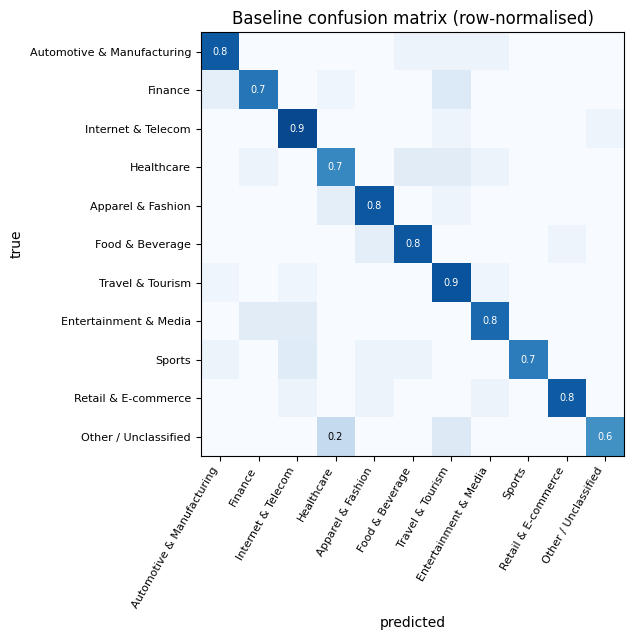

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
cm = confusion_matrix(test.true_vertical, test.pred, labels=LABELS, normalize="true")
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS, fontsize=8)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Baseline confusion matrix (row-normalised)")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        if cm[i, j] >= 0.15:
            ax.text(j, i, f"{cm[i, j]:.1f}", ha="center", va="center", fontsize=7,
                    color="white" if cm[i, j] > 0.5 else "black")
plt.tight_layout(); plt.show()

## Step 6 - Error analysis

Which mistakes cost the most? Sort the misclassified test advertisers by revenue.

In [12]:
wrong = test[test.pred != test.true_vertical].sort_values("revenue_usd", ascending=False)
wrong[["advertiser", "true_vertical", "pred", "revenue_usd", "tier"]].head(12).round(0).reset_index(drop=True)

,advertiser,true_vertical,pred,revenue_usd,tier
0,ITV,Entertainment & Media,Finance,2030083.0,tier1_top90pct
1,Zara,Apparel & Fashion,Healthcare,1577949.0,tier1_top90pct
2,UEFA,Sports,Automotive & Manufacturing,1529466.0,tier1_top90pct
3,Ralph Lauren,Apparel & Fashion,Healthcare,1283995.0,tier1_top90pct
4,O2,Internet & Telecom,Other / Unclassified,1075981.0,tier1_top90pct
5,Admiral,Finance,Travel & Tourism,1059312.0,tier1_top90pct
6,Netflix,Entertainment & Media,Internet & Telecom,768669.0,tier1_top90pct
7,Kellogg's,Food & Beverage,Apparel & Fashion,566092.0,tier1_top90pct
8,Tripadvisor,Travel & Tourism,Internet & Telecom,558471.0,tier1_top90pct
9,Virgin Atlantic,Travel & Tourism,Automotive & Manufacturing,516398.0,tier1_top90pct


**What the errors say (read the table above to confirm on your own run):**
- The costly mistakes are almost all **real brand names** whose text carries no hint of the industry (the table above shows accuracy on real brands is far below accuracy on descriptive names). A character model cannot know that `Lidl` sells groceries or that `Haleon` is healthcare; it only sees letters.
- That is a **knowledge** problem, not a tuning problem. More regularisation or more n-grams will not fix it.
- The descriptive tail names are easy, because the words themselves signal the vertical.

This is the motivation for notebook 03: bring in **world knowledge** (pretrained sentence embeddings, and optionally an LLM for the low-confidence cases) and see whether it fixes exactly these errors.

**Caveat to state in interviews:** this is synthetic data. The tail names were generated from keyword pools, so tail accuracy here is optimistic compared with real obscure advertiser names. The real-brand-name result is the more informative one.

## Step 7 - Save outputs for notebook 03

Baseline predictions come with a **confidence** (the highest class probability). Notebook 03 will use confidence to decide which advertisers go to a stronger model or to a human.

In [13]:
proba = baseline.predict_proba(adv.advertiser)
adv["baseline_pred"] = baseline.classes_[proba.argmax(axis=1)]
adv["baseline_conf"] = proba.max(axis=1)

adv.drop(columns=["cluster"], errors="ignore").to_csv(OUT / "advertisers_labeled.csv", index=False)
print("saved", OUT / "advertisers_labeled.csv")
print(adv.split.value_counts().to_dict())

saved /home/claude/advertiser-classification/data/processed/advertisers_labeled.csv
{'unlabeled': 1557, 'train': 603, 'test': 202}


## Takeaways

- **Spend labeling effort by revenue:** all top advertisers (90% of revenue) plus a tail sample gives a labeled set that is small but covers the money.
- **Hold out first, tune on train only:** the test set was untouched until the final evaluation.
- **Report by revenue and by tier**, not just overall accuracy: the headline number is flattered by easy tail names.
- **Baseline fails where it matters** (real brands with uninformative names), which justifies a model with world knowledge.

**Next:** `03_embeddings_and_confidence` - sentence embeddings, a confidence threshold, and a side-by-side comparison with this baseline.